# Generation Rent – 01 · Load, clean and reshape

**Project question:** *Can young Europeans still afford a home?*

This notebook takes the 9 raw Eurostat files (8 datasets) in `datasets/eurostat-*` and produces tidy, analysis-ready tables in `clean/generation-rent/` (next to this notebook's folder) for the SQL and Power BI steps.

**What you'll practise**
1. Writing one reusable cleaning function instead of copy-pasting code 9 times
2. Splitting `code: label` text into two columns
3. Converting text to numbers and keeping data-quality flags
4. Filtering a "long" table down to the slice you actually need (and *not* double counting)
5. Reshaping long → wide and joining tables into one country-year table
6. Writing data-quality checks you can show in an interview

> Raw files are never modified. Everything is written to `clean/`.

## 1 · Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# BASE = the folder that holds python/, clean/ and sql/ (one level up from this notebook).
# ROOT = the project root: the first folder at or above BASE that contains datasets/.
# This works whether the notebook sits in DataStudy/python/ or in DataStudy/pipeline/python/.
HERE = Path.cwd()
BASE = HERE.parent if HERE.name == "python" else HERE
ROOT = next((p for p in [BASE, *BASE.parents] if (p / "datasets").is_dir()), None)
assert ROOT is not None, f"No datasets/ folder found at or above {BASE}"
RAW = ROOT / "datasets"
OUT = BASE / "clean" / "generation-rent"
OUT.mkdir(parents=True, exist_ok=True)
print("raw data from:", RAW.relative_to(ROOT))      # relative paths: no personal folder names in outputs
print("outputs to:   ", OUT.relative_to(ROOT))

FILES = {
    "hpi_a":        RAW / "eurostat-house-price-index" / "prc_hpi_a.csv",
    "hpi_q":        RAW / "eurostat-house-price-index" / "prc_hpi_q.csv",
    "ptir":         RAW / "eurostat-house-price-to-income" / "tipsho60.csv",
    "net_earn":     RAW / "eurostat-net-earnings" / "earn_nt_net.csv",
    "city_rents":   RAW / "eurostat-city-rents" / "prc_colc_rents.csv",
    "overburden":   RAW / "eurostat-housing-cost-overburden" / "ilc_lvho07a.csv",
    "age_leave":    RAW / "eurostat-age-leaving-home" / "yth_demo_030.csv",
    "with_parents": RAW / "eurostat-young-adults-living-with-parents" / "ilc_lvps08.csv",
    "hicp":         RAW / "eurostat-hicp-housing-food" / "prc_hicp_minr.csv",
}
for name, path in FILES.items():
    print(f"{name:13} {'OK ' if path.exists() else 'MISSING'} {path.relative_to(ROOT)}")

raw data from: datasets
outputs to:    pipeline\clean\generation-rent
hpi_a         OK  datasets\eurostat-house-price-index\prc_hpi_a.csv
hpi_q         OK  datasets\eurostat-house-price-index\prc_hpi_q.csv
ptir          OK  datasets\eurostat-house-price-to-income\tipsho60.csv
net_earn      OK  datasets\eurostat-net-earnings\earn_nt_net.csv
city_rents    OK  datasets\eurostat-city-rents\prc_colc_rents.csv
overburden    OK  datasets\eurostat-housing-cost-overburden\ilc_lvho07a.csv
age_leave     OK  datasets\eurostat-age-leaving-home\yth_demo_030.csv
with_parents  OK  datasets\eurostat-young-adults-living-with-parents\ilc_lvps08.csv
hicp          OK  datasets\eurostat-hicp-housing-food\prc_hicp_minr.csv


## 2 · Look at one raw file first

Always look before you clean. Notice two things:
- Column names look like `geo: Geopolitical entity (reporting)`
- Values look like `PT: Portugal`, so the code and the label are stuck together in one cell

In [2]:
raw = pd.read_csv(FILES["age_leave"], dtype=str, keep_default_na=False)
print(raw.shape)
raw.head()

(2331, 10)


,STRUCTURE,STRUCTURE_ID,freq: Time frequency,unit: Unit of measure,sex: Sex,geo: Geopolitical entity (reporting),TIME_PERIOD: Time,OBS_VALUE: Observation value,OBS_FLAG: Observation status (Flag) V2 structure,CONF_STATUS: Confidentiality status (flag)
0,dataflow,ESTAT:YTH_DEMO_030(1.0),A: Annual,AVG: Average,F: Females,AT: Austria,2004,23.9,,
1,dataflow,ESTAT:YTH_DEMO_030(1.0),A: Annual,AVG: Average,F: Females,AT: Austria,2005,24.1,,
2,dataflow,ESTAT:YTH_DEMO_030(1.0),A: Annual,AVG: Average,F: Females,AT: Austria,2006,24.1,,
3,dataflow,ESTAT:YTH_DEMO_030(1.0),A: Annual,AVG: Average,F: Females,AT: Austria,2007,24.0,,
4,dataflow,ESTAT:YTH_DEMO_030(1.0),A: Annual,AVG: Average,F: Females,AT: Austria,2008,24.2,,


## 3 · One cleaning function for all files

`clean_eurostat()` does the same steps for every file:

| Step | Why |
|---|---|
| Read everything as text (`dtype=str`) | So pandas doesn't guess types wrongly (e.g. `2015` as a number, `""` as NaN) |
| Drop `STRUCTURE`, `STRUCTURE_ID`, `CONF_STATUS` | Metadata, the same on every row |
| Rename `geo: Geopolitical entity` → `geo` | Short, SQL-friendly names |
| Split `PT: Portugal` → `geo` = `PT`, `geo_label` = `Portugal` | Codes for joining/filtering, labels for charts |
| `OBS_VALUE` → `value` (float) | Empty string → missing (NaN) |
| `OBS_FLAG` → `flag` (code) + `flag_label` | Keep quality information. Never silently drop it |

`str.split(": ", n=1)` splits only on the **first** `": "`, because some labels contain a colon themselves.

In [3]:
DROP_COLS = {"STRUCTURE", "STRUCTURE_ID", "CONF_STATUS"}

def clean_eurostat(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    df = df[[c for c in df.columns if c.split(":")[0] not in DROP_COLS]]
    df.columns = [c.split(":")[0].strip() for c in df.columns]   # 'geo: Geopolitical…' -> 'geo'

    df = df.rename(columns={"TIME_PERIOD": "time", "OBS_VALUE": "value", "OBS_FLAG": "flag"})
    out = pd.DataFrame(index=df.index)

    for col in df.columns:
        if col in ("time", "value"):
            continue
        parts = df[col].str.split(": ", n=1, expand=True)
        out[col] = parts[0].str.strip()
        # A column with no ': ' anywhere (e.g. an all-empty flag column) has no label part
        out[f"{col}_label"] = parts[1].str.strip() if parts.shape[1] > 1 else pd.NA

    out["time"] = df["time"].str.strip()
    out["value"] = pd.to_numeric(df["value"].replace("", pd.NA), errors="coerce")
    out["flag"] = out["flag"].replace("", pd.NA)
    if "freq" in out:                       # every row has the same frequency inside one file
        out = out.drop(columns=["freq", "freq_label"], errors="ignore")
    return out

age_leave = clean_eurostat(FILES["age_leave"])
age_leave.head()

,unit,unit_label,sex,sex_label,geo,geo_label,flag,flag_label,time,value
0,AVG,Average,F,Females,AT,Austria,NaN,NaN,2004,23.9
1,AVG,Average,F,Females,AT,Austria,NaN,NaN,2005,24.1
2,AVG,Average,F,Females,AT,Austria,NaN,NaN,2006,24.1
3,AVG,Average,F,Females,AT,Austria,NaN,NaN,2007,24.0
4,AVG,Average,F,Females,AT,Austria,NaN,NaN,2008,24.2


## 4 · Clean all 9 files

In [4]:
data = {name: clean_eurostat(path) for name, path in FILES.items()}

summary = pd.DataFrame({
    name: {
        "rows": len(df),
        "missing values": int(df["value"].isna().sum()),
        "flagged rows": int(df["flag"].notna().sum()),
        "countries/geos": df["geo"].nunique(),
        "first period": df["time"].min(),
        "last period": df["time"].max(),
    }
    for name, df in data.items()
}).T
summary

,rows,missing values,flagged rows,countries/geos,first period,last period
hpi_a,6114,156,169,38,2005,2025
hpi_q,33617,864,951,38,2005-Q1,2026-Q2
ptir,2161,0,539,29,2000,2025
net_earn,199986,0,6786,40,2000,2025
city_rents,5416,0,0,44,2013,2025
overburden,127035,176,15564,46,2003,2025
age_leave,2331,0,195,36,2000,2025
with_parents,22086,0,1089,46,2003,2025
hicp,266075,0,24244,46,1996-01,2026-10


## 5 · Countries vs aggregates

Every file mixes real countries with **overlapping aggregates** (`EU`, `EU27_2020`, `EU28`, `EA`, `EA20`, `EEA`…).
If you rank or sum without removing them, totals are wrong. We build one **country dimension** and mark:
- `is_eu27`: the 27 current EU member states
- `is_aggregate`: EU / euro-area / European Economic Area groupings (we keep only `EU27_2020` as "the EU average")
- `in_country_year` (added in section 8): does this geo appear in the main table? Use it to keep Power BI slicers clean.

Note: Eurostat uses `EL` for Greece and `UK` for the United Kingdom (not ISO `GR` / `GB`). Power BI maps need ISO codes, so we add `iso2`.
Aggregates get **no** `iso2` (a map can't place "EU27_2020").

In [5]:
EU27 = ["AT","BE","BG","CY","CZ","DE","DK","EE","EL","ES","FI","FR","HR","HU","IE","IT",
        "LT","LU","LV","MT","NL","PL","PT","RO","SE","SI","SK"]

geo_labels = (
    pd.concat([df[["geo", "geo_label"]] for k, df in data.items() if k != "city_rents"])
      .drop_duplicates("geo")
      .set_index("geo")["geo_label"]
)
dim_country = pd.DataFrame({"geo": geo_labels.index, "country": geo_labels.values})
dim_country["is_eu27"] = dim_country["geo"].isin(EU27)
dim_country["is_aggregate"] = dim_country["geo"].str.match(r"^(EU|EA|EEA)")   # EEA = European Economic Area
dim_country["iso2"] = (dim_country["geo"].replace({"EL": "GR", "UK": "GB"})
                         .where(~dim_country["is_aggregate"]))                 # no ISO code for aggregates
dim_country.loc[dim_country["geo"] == "EU27_2020", "country"] = "EU average (27)"
dim_country = dim_country.sort_values(["is_aggregate", "geo"]).reset_index(drop=True)

print(dim_country["is_eu27"].sum(), "EU27 countries found (expected 27)")
dim_country[dim_country["is_aggregate"]]

27 EU27 countries found (expected 27)


,geo,country,is_eu27,is_aggregate,iso2
41,EA,"Euro area (EA11-1999, EA12-2001, EA13-2007, EA...",False,True,NaN
42,EA18,Euro area - 18 countries (2014),False,True,NaN
43,EA19,Euro area - 19 countries (2015-2022),False,True,NaN
44,EA20,Euro area – 20 countries (2023-2025),False,True,NaN
45,EA21,Euro area – 21 countries (from 2026),False,True,NaN
46,EEA,"European Economic Area (EEA18-1995, EEA28-2004...",False,True,NaN
47,EU,"European Union (EU6-1958, EU9-1973, EU10-1981,...",False,True,NaN
48,EU15,European Union - 15 countries (1995-2004),False,True,NaN
49,EU27_2007,European Union - 27 countries (2007-2013),False,True,NaN
50,EU27_2020,EU average (27),False,True,NaN


## 6 · Data-quality flags: what's in the data?

Flags matter for the story. `b` (break in series) means **don't compare across that year**. `u` means low reliability.

In [6]:
flags = (
    pd.concat([df.assign(dataset=k)[["dataset", "flag", "flag_label"]] for k, df in data.items()])
      .dropna(subset=["flag"])
      .value_counts()
      .rename("rows")
      .reset_index()
)
flags

,dataset,flag,flag_label,rows
0,hicp,d,definition differs (see metadata),17963
1,overburden,e,estimated,7705
2,net_earn,b,break in time series,6786
3,hicp,e,estimated,5949
4,overburden,b,break in time series,4308
5,overburden,u,low reliability,3027
6,with_parents,e,estimated,540
7,ptir,e,estimated,512
8,with_parents,b,break in time series,495
9,hpi_q,d,definition differs (see metadata),476


### The 2024 net-earnings break (a good example to mention in interviews)

Net earnings for a single average-wage worker in Portugal jump ~31% between 2023 and 2024, and 2024 is flagged `b`.
A real pay rise that size is implausible. And the second table shows **every EU country** is flagged `b` in 2024:
it's an EU-wide change in method, not a Portuguese story.
**Rule for this project:** never present 2023 → 2024 earnings growth as real. Compare 2015 → 2023 and 2024 → 2025 separately.

In [7]:
ne = data["net_earn"]
single = ne[(ne.estruct == "NET") & (ne.currency == "EUR") & (ne.ecase == "P1_NCH_AW100")]
display(single[single.geo == "PT"][["time", "value", "flag", "flag_label"]].tail(6))

eu27_2024 = single[single.geo.isin(EU27) & (single.time == "2024")]
print(f"EU27 countries with a 2024 value: {len(eu27_2024)}, of which flagged 'b': {(eu27_2024.flag == 'b').sum()}")

,time,value,flag,flag_label
29594,2020,12934.79,NaN,NaN
29595,2021,13502.54,NaN,NaN
29596,2022,14213.56,NaN,NaN
29597,2023,15301.09,NaN,NaN
29598,2024,20098.79,b,break in time series
29599,2025,21449.05,NaN,NaN


EU27 countries with a 2024 value: 27, of which flagged 'b': 27


## 7 · Pick the right slice of each table

Each raw table has many dimensions. For the headline country-year table we choose **one** value per dimension.
These choices are the analysis, so write them down. You'll be asked "why that measure?" in an interview.

| Measure | Table | Filter |
|---|---|---|
| `house_price_index_2015` | hpi_a | `purchase=TOTAL`, `unit=I15_A_AVG` (2015 = 100) |
| `net_earnings_eur`, `net_earnings_pps` | net_earn | `estruct=NET`, `ecase=P1_NCH_AW100` (single, no kids, average wage), currency EUR / PPS |
| `price_to_income_vs_lt_avg` | ptir | `unit=PTIR_LT_AVG` (100 = country's long-term average) |
| `overburden_total`, `overburden_18_24`, `overburden_25_29` | overburden | `sex=T`, `rskpovth=TOTAL`, age TOTAL / Y18-24 / Y25-29 |
| `age_leaving_home` | age_leave | `sex=T` |
| `pct_18_34_with_parents` | with_parents | `sex=T`, `age=Y18-34` |
| `hicp_rent_index`, `hicp_all_index` | hicp | annual **average** of monthly `I15` for `CP041` / `TOTAL` (full years only) |

The helper `pick()` filters, then **checks there is exactly one row per country-year**. If not, a filter is missing and we'd be double counting.

In [8]:
def pick(df: pd.DataFrame, name: str, **filters) -> pd.DataFrame:
    """Filter a clean Eurostat table to one series per geo-year and return geo, year, <name>, <name>_flag."""
    sub = df
    for col, val in filters.items():
        sub = sub[sub[col] == val]
    dupes = sub.duplicated(["geo", "time"]).sum()
    assert dupes == 0, f"{name}: {dupes} duplicate geo-year rows. Add another filter!"
    return (sub[["geo", "time", "value", "flag"]]
              .rename(columns={"time": "year", "value": name, "flag": f"{name}_flag"}))

d = data
measures = [
    pick(d["hpi_a"], "house_price_index_2015", purchase="TOTAL", unit="I15_A_AVG"),
    pick(d["net_earn"], "net_earnings_eur", estruct="NET", ecase="P1_NCH_AW100", currency="EUR"),
    pick(d["net_earn"], "net_earnings_pps", estruct="NET", ecase="P1_NCH_AW100", currency="PPS"),
    pick(d["ptir"], "price_to_income_vs_lt_avg", unit="PTIR_LT_AVG"),
    pick(d["overburden"], "overburden_total", sex="T", rskpovth="TOTAL", age="TOTAL"),
    pick(d["overburden"], "overburden_18_24", sex="T", rskpovth="TOTAL", age="Y18-24"),
    pick(d["overburden"], "overburden_25_29", sex="T", rskpovth="TOTAL", age="Y25-29"),
    pick(d["age_leave"], "age_leaving_home", sex="T"),
    pick(d["with_parents"], "pct_18_34_with_parents", sex="T", age="Y18-34"),
]
[m.shape for m in measures]

[(759, 4),
 (892, 4),
 (892, 4),
 (730, 4),
 (833, 4),
 (833, 4),
 (833, 4),
 (777, 4),
 (826, 4)]

### HICP: monthly → annual

HICP is monthly, everything else is annual. We average the 12 monthly index values per year,
and **only keep years with all 12 months** (otherwise 2026 would be an average of 9–10 months and look wrong).

In [9]:
h = d["hicp"][(d["hicp"].unit == "I15") & d["hicp"].coicop18.isin(["CP041", "TOTAL"])].copy()
h["year"] = h["time"].str[:4]
hicp_year = (h.groupby(["geo", "year", "coicop18"])["value"]
               .agg(["mean", "count"]).reset_index())
hicp_year = hicp_year[hicp_year["count"] == 12]
hicp_wide = (hicp_year.pivot(index=["geo", "year"], columns="coicop18", values="mean")
               .rename(columns={"CP041": "hicp_rent_index", "TOTAL": "hicp_all_index"})
               .reset_index())
hicp_wide.columns.name = None
hicp_wide.tail()

,geo,year,hicp_rent_index,hicp_all_index
1186,XK,2021,97.475000,109.347500
1187,XK,2022,97.720000,122.010000
1188,XK,2023,99.720000,128.043333
1189,XK,2024,100.345000,130.116667
1190,XK,2025,101.343333,135.137500


## 8 · Join everything into one country-year table

In [10]:
from functools import reduce

country_year = reduce(lambda a, b: a.merge(b, on=["geo", "year"], how="outer", validate="one_to_one"),
                      measures + [hicp_wide])
country_year = country_year.merge(dim_country[["geo", "country", "iso2", "is_eu27"]], on="geo", how="left",
                                  validate="many_to_one")

# Keep EU27 countries + the EU27 average, years 2005-2025
keep = country_year["is_eu27"] | (country_year["geo"] == "EU27_2020")
country_year = country_year[keep & country_year["year"].between("2005", "2025")]
country_year["year"] = country_year["year"].astype(int)

# Derived measure: real house prices (house prices relative to general inflation), 2015 = 100
country_year["real_house_price_index_2015"] = (
    country_year["house_price_index_2015"] / country_year["hicp_all_index"] * 100
)

front = ["geo", "country", "iso2", "year"]
country_year = country_year[front + [c for c in country_year.columns if c not in front + ["is_eu27"]]]
country_year = country_year.sort_values(["geo", "year"]).reset_index(drop=True)

# Flag the dimension rows that actually have data here (for clean Power BI slicers)
dim_country["in_country_year"] = dim_country["geo"].isin(country_year["geo"])

print(country_year.shape)
country_year[country_year.geo == "PT"].tail(4).T

(588, 25)


,500,501,502,503
geo,PT,PT,PT,PT
country,Portugal,Portugal,Portugal,Portugal
iso2,PT,PT,PT,PT
year,2022,2023,2024,2025
house_price_index_2015,190.17,205.76,224.44,263.85
house_price_index_2015_flag,NaN,NaN,NaN,NaN
net_earnings_eur,14213.56,15301.09,20098.79,21449.05
net_earnings_eur_flag,NaN,NaN,b,NaN
net_earnings_pps,16282.42,17639.02,23112.76,24665.51
net_earnings_pps_flag,NaN,NaN,b,NaN


## 9 · City rents vs national net salary

`prc_colc_rents` comes from Eurostat's **correction coefficients** (used to adjust EU officials' pay by duty station),
so these rents are **not** the average local rent. Label them that way in every chart.

We compare the monthly rent of a **1-bedroom flat** in each city with **1/12 of the national annual net salary**
of a single average-wage worker. (A city rent against a national wage: also say this in the chart note.)

Two things to know about the cities:
- Not all of them are capitals. Codes ending in `_DEL` are other duty stations (Munich, Bonn, Karlsruhe, Varese, Geneva, Culham, Den Haag).
  The column `is_capital` marks the `_CAP` codes. **The Netherlands has no capital in this data** (only Den Haag), so "EU capitals" = 26.
- Because of the **2024 earnings break**, the rent share is only comparable **within one year**. Lisbon drops from 105.9% (2023)
  to 78.3% (2025) mostly because the earnings method changed, not because rent became cheaper. Never draw it as one trend line across 2024.

In [11]:
cr = d["city_rents"]
rent = cr[(cr.currency == "EUR") & (cr.building == "FLAT1")].copy()
rent["country_geo"] = rent["geo"].str.split("_").str[0]
rent["is_capital"] = rent["geo"].str.endswith("_CAP")
rent = rent.rename(columns={"geo": "city_geo", "geo_label": "city", "time": "year",
                            "value": "rent_1bed_eur_month"})

net_eur = measures[1].rename(columns={"geo": "country_geo"})
city_rent = rent.merge(net_eur, on=["country_geo", "year"], how="left", validate="many_to_one")
city_rent["net_salary_eur_month"] = city_rent["net_earnings_eur"] / 12
city_rent["rent_share_of_net_salary_pct"] = (
    city_rent["rent_1bed_eur_month"] / city_rent["net_salary_eur_month"] * 100).round(1)
city_rent["year"] = city_rent["year"].astype(int)
city_rent = city_rent[["city_geo", "city", "country_geo", "is_capital", "year", "rent_1bed_eur_month",
                       "net_salary_eur_month", "rent_share_of_net_salary_pct", "net_earnings_eur_flag"]]

latest = city_rent[(city_rent.year == 2025) & city_rent.is_capital].dropna(subset=["rent_share_of_net_salary_pct"])
latest.sort_values("rent_share_of_net_salary_pct", ascending=False).head(10)

,city_geo,city,country_geo,is_capital,year,rent_1bed_eur_month,net_salary_eur_month,rent_share_of_net_salary_pct,net_earnings_eur_flag
446,PT_CAP,Lisboa,PT,True,2025,1400,1787.420833,78.3,NaN
251,HR_CAP,Zagreb,HR,True,2025,1050,1407.660833,74.6,NaN
115,CZ_CAP,Praha,CZ,True,2025,1250,1741.744167,71.8,NaN
264,HU_CAP,Budapest,HU,True,2025,910,1285.999167,70.8,NaN
485,SE_CAP,Stockholm,SE,True,2025,2100,3245.795833,64.7,NaN
199,EL_CAP,Athina,EL,True,2025,1150,1791.522500,64.2,NaN
511,SK_CAP,Bratislava,SK,True,2025,910,1508.050833,60.3,NaN
459,RO_CAP,Bucuresti,RO,True,2025,670,1156.449167,57.9,NaN
212,ES_CAP,Madrid,ES,True,2025,1300,2253.393333,57.7,NaN
238,FR_CAP,Paris,FR,True,2025,1550,2695.503333,57.5,NaN


## 9b · Power BI helper tables: monthly inflation and a year dimension

**`hicp_monthly`** (monthly inflation, EU27 + EU average). The raw table is long, with **two units in one value column**
(`I15` = index 2015 = 100, `RCH_A` = annual rate of change in %). Summing or averaging that column in Power BI would mix
an index with a percentage. So we pivot the unit into two columns, `index_2015` and `annual_rate_pct`, each with its own flag,
and add a real `date` (first day of the month) plus `year` for the relationship to `dim_year`.
The newest month is often a *flash estimate* with only a few categories. Use the latest **complete** month (see SQL file 05).

**`dim_year`**: one row per year, 1996–2026 (the full span of all tables), so `country_year`, `city_rent` and `hicp_monthly`
can share one year slicer. `earnings_series` marks the 2024 method break, so visuals can split earnings-based lines at 2024.

In [12]:
hm = d["hicp"][d["hicp"].geo.isin(EU27 + ["EU27_2020"])]
keys = ["geo", "coicop18", "coicop18_label", "time"]
hicp_monthly = hm.pivot(index=keys, columns="unit", values=["value", "flag"])
hicp_monthly.columns = [f"{v}_{u}" for v, u in hicp_monthly.columns]
hicp_monthly = (hicp_monthly.reset_index()
                .rename(columns={"time": "month", "value_I15": "index_2015", "flag_I15": "index_2015_flag",
                                 "value_RCH_A": "annual_rate_pct", "flag_RCH_A": "annual_rate_pct_flag"}))
hicp_monthly["date"] = pd.to_datetime(hicp_monthly["month"] + "-01", format="%Y-%m-%d")
hicp_monthly["year"] = hicp_monthly["date"].dt.year
hicp_monthly = hicp_monthly[["geo", "coicop18", "coicop18_label", "month", "date", "year",
                             "index_2015", "index_2015_flag", "annual_rate_pct", "annual_rate_pct_flag"]]
hicp_monthly = hicp_monthly.sort_values(["geo", "coicop18", "month"]).reset_index(drop=True)

# Nothing lost in the pivot: every long row became exactly one filled cell
assert hicp_monthly[["index_2015", "annual_rate_pct"]].notna().sum().sum() == len(hm)
print(f"hicp long rows {len(hm):,} -> wide rows {len(hicp_monthly):,}")

all_years = pd.concat([country_year["year"], city_rent["year"], hicp_monthly["year"]])
dim_year = pd.DataFrame({"year": range(int(all_years.min()), int(all_years.max()) + 1)})
dim_year["earnings_series"] = np.where(dim_year["year"] >= 2024, "2024+ (new method)", "up to 2023")
dim_year["in_country_year"] = dim_year["year"].between(country_year["year"].min(), country_year["year"].max())
dim_year.head(3)

hicp long rows 196,331 -> wide rows 99,856


,year,earnings_series,in_country_year
0,1996,up to 2023,False
1,1997,up to 2023,False
2,1998,up to 2023,False


## 10 · Data-quality checks

Small automated checks that catch the most common mistakes. If any fails, the notebook stops.

**Gotcha:** a comparison with a missing value (`NaN >= 0`) is `False`, so a naive check fails just because some
country-years have no data. We therefore check *"no value breaks the rule"* (`(df < 0).any()`), which ignores NaN,
and report missing values separately.

In [13]:
num = country_year.select_dtypes("number").drop(columns="year")
pct = country_year[["overburden_total", "overburden_18_24", "overburden_25_29", "pct_18_34_with_parents"]]

checks = {
    "one row per geo-year": not country_year.duplicated(["geo", "year"]).any(),
    "exactly the 27 EU countries + EU average": set(country_year["geo"]) == set(EU27) | {"EU27_2020"},
    "no negative values": not (num < 0).any().any(),
    "percentages between 0 and 100": not ((pct < 0) | (pct > 100)).any().any(),
    "age leaving home plausible (15-40)": country_year["age_leaving_home"].dropna().between(15, 40).all(),
    "city rents positive": (city_rent["rent_1bed_eur_month"] > 0).all(),
    "one row per city-year": not city_rent.duplicated(["city_geo", "year"]).any(),
    "one row per hicp geo-category-month": not hicp_monthly.duplicated(["geo", "coicop18", "month"]).any(),
    "every fact geo is in dim_country": set(country_year.geo) | set(city_rent.country_geo) | set(hicp_monthly.geo) <= set(dim_country.geo),
    "every fact year is in dim_year": set(all_years) <= set(dim_year.year),
    "no ISO code on aggregates": dim_country.loc[dim_country.is_aggregate, "iso2"].isna().all(),
}
for k, v in checks.items():
    print(("PASS " if v else "FAIL ") + k)
assert all(checks.values()), "A data-quality check failed. Investigate before exporting."

print("\nMissing values per measure (country-years without data):")
print(num.isna().sum()[lambda s: s > 0].sort_values(ascending=False).to_string())

coverage = country_year.notna().groupby(country_year["year"]).mean().round(2)
coverage.loc[[2005, 2015, 2024, 2025]].T

PASS one row per geo-year
PASS exactly the 27 EU countries + EU average
PASS no negative values
PASS percentages between 0 and 100
PASS age leaving home plausible (15-40)
PASS city rents positive
PASS one row per city-year
PASS one row per hicp geo-category-month
PASS every fact geo is in dim_country
PASS every fact year is in dim_year
PASS no ISO code on aggregates

Missing values per measure (country-years without data):
house_price_index_2015         59
real_house_price_index_2015    59
net_earnings_eur               30
net_earnings_pps               30
overburden_total               19
overburden_18_24               19
overburden_25_29               19
pct_18_34_with_parents         12
age_leaving_home               10


year,2005,2015,2024,2025
geo,1.00,1.00,1.00,1.00
country,1.00,1.00,1.00,1.00
iso2,0.96,0.96,0.96,0.96
year,1.00,1.00,1.00,1.00
house_price_index_2015,0.46,0.96,0.96,0.96
house_price_index_2015_flag,0.04,0.07,0.04,0.07
net_earnings_eur,0.86,0.96,1.00,1.00
net_earnings_eur_flag,0.00,0.00,1.00,0.00
net_earnings_pps,0.86,0.96,1.00,1.00
net_earnings_pps_flag,0.00,0.00,1.00,0.00


## 11 · Quick sanity chart

Not the final visual (that's for Power BI). Just checking the numbers make sense.

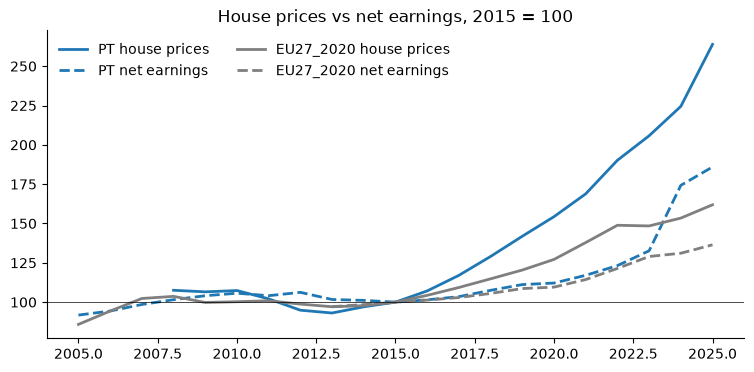

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
for geo, colour in [("PT", "#1f77b4"), ("EU27_2020", "#7f7f7f")]:
    s = country_year[country_year.geo == geo].set_index("year")
    ax.plot(s.index, s["house_price_index_2015"], color=colour, lw=2, label=f"{geo} house prices")
    ax.plot(s.index, s["net_earnings_eur"] / s.loc[2015, "net_earnings_eur"] * 100,
            color=colour, lw=2, ls="--", label=f"{geo} net earnings")
ax.axhline(100, color="black", lw=0.5)
ax.set_title("House prices vs net earnings, 2015 = 100")
ax.legend(frameon=False, ncol=2)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 12 · Export

- **Tidy long tables** (`long_*.csv`): every cleaned row, all dimensions. For SQL practice and drill-downs.
- **Analysis tables for Power BI**: `country_year.csv`, `city_rent.csv` (facts), `dim_country.csv`, `dim_year.csv` (dimensions),
  `hicp_monthly.csv` (monthly inflation, one column per unit).

CSV with UTF-8 (BOM, so Excel shows accents like *München* correctly), dot as the decimal separator.

In [15]:
def save(df: pd.DataFrame, name: str):
    path = OUT / f"{name}.csv"
    df.to_csv(path, index=False, encoding="utf-8-sig")
    print(f"{name:28} {len(df):>8,} rows  ->  {path.relative_to(ROOT)}")

for name, df in data.items():
    save(df, f"long_{name}")

save(hicp_monthly, "hicp_monthly")
save(dim_country, "dim_country")
save(dim_year, "dim_year")
save(country_year, "country_year")
save(city_rent, "city_rent")

long_hpi_a                      6,114 rows  ->  pipeline\clean\generation-rent\long_hpi_a.csv
long_hpi_q                     33,617 rows  ->  pipeline\clean\generation-rent\long_hpi_q.csv
long_ptir                       2,161 rows  ->  pipeline\clean\generation-rent\long_ptir.csv


long_net_earn                 199,986 rows  ->  pipeline\clean\generation-rent\long_net_earn.csv
long_city_rents                 5,416 rows  ->  pipeline\clean\generation-rent\long_city_rents.csv
long_overburden               127,035 rows  ->  pipeline\clean\generation-rent\long_overburden.csv


long_age_leave                  2,331 rows  ->  pipeline\clean\generation-rent\long_age_leave.csv
long_with_parents              22,086 rows  ->  pipeline\clean\generation-rent\long_with_parents.csv


long_hicp                     266,075 rows  ->  pipeline\clean\generation-rent\long_hicp.csv
hicp_monthly                   99,856 rows  ->  pipeline\clean\generation-rent\hicp_monthly.csv
dim_country                        52 rows  ->  pipeline\clean\generation-rent\dim_country.csv
dim_year                           31 rows  ->  pipeline\clean\generation-rent\dim_year.csv
country_year                      588 rows  ->  pipeline\clean\generation-rent\country_year.csv
city_rent                         552 rows  ->  pipeline\clean\generation-rent\city_rent.csv


## Next steps
1. **SQL** (`sql/`): load `clean/generation-rent/*.csv` into DuckDB (already installed) or Databricks and answer the headline questions with queries.
2. **Power BI** (`powerbi/`): import `country_year`, `city_rent`, `hicp_monthly` (facts) and `dim_country`, `dim_year` (dimensions).
   - Relationships: `dim_country[geo]` → `country_year[geo]`, `city_rent[country_geo]`, `hicp_monthly[geo]`; `dim_year[year]` → the `year` column of each fact.
   - If Power BI shows numbers 100× too big, set *Options → Regional settings → Import locale = English*.
   - Set **Summarize by = None** on every value column (they are indices, rates and averages: adding them up is meaningless) and use DAX measures.
3. **Write down caveats** for the dashboard: city rents = EU-staff duty-station rents. Net earnings have an EU-wide break in 2024 (so the rent share is comparable only within one year). EU-SILC values flagged `u` = low reliability. No Greek house-price data; 26 EU capitals (no Dutch capital).